<a href="https://colab.research.google.com/github/medhuuuu/swedish-retrieval-project/blob/main/notebooks/04_hybrid_retrieval.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Install Libraries

In [3]:
!pip install rank-bm25

# Import Library

In [4]:
from datasets import load_dataset, concatenate_datasets
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer
import numpy as np
import pandas as pd

# Data Load

In [5]:
# SweFAQ
swefaq_corpus = load_dataset("mteb/SweFaqRetrieval", "corpus")["test"]
swefaq_queries = load_dataset("mteb/SweFaqRetrieval", "queries")["test"]
swefaq_qrels = load_dataset("mteb/SweFaqRetrieval", "qrels")["test"]

# SwednRetrieval (merged splits)
splits = ["train", "validation", "test"]
all_corpus, all_queries, all_qrels = [], [], []
for split in splits:
    corpus_split = load_dataset("mteb/SwednRetrieval", "corpus")[split].map(lambda x: {"_id": f"{split}_{x['_id']}"})
    queries_split = load_dataset("mteb/SwednRetrieval", "queries")[split].map(lambda x: {"_id": f"{split}_{x['_id']}"})
    qrels_split = load_dataset("mteb/SwednRetrieval", "qrels")[split].map(lambda x: {
        "query-id": f"{split}_{x['query-id']}", "corpus-id": f"{split}_{x['corpus-id']}"
    })
    all_corpus.append(corpus_split); all_queries.append(queries_split); all_qrels.append(qrels_split)

swedn_corpus = concatenate_datasets(all_corpus)
swedn_queries = concatenate_datasets(all_queries)
swedn_qrels = concatenate_datasets(all_qrels)

def build_qrels_dict(qrels):
    d = {}
    for row in qrels:
        d.setdefault(row["query-id"], set()).add(row["corpus-id"])
    return d

swefaq_qrels_dict = build_qrels_dict(swefaq_qrels)
swedn_qrels_dict = build_qrels_dict(swedn_qrels)

README.md:   0%|          | 0.00/6.41k [00:00<?, ?B/s]

corpus/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 88.9kB            

corpus/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/511 [00:00<?, ? examples/s]

queries/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.5kB            

...

Map:   0%|          | 0/1024 [00:00<?, ? examples/s]

Map:   0%|          | 0/2048 [00:00<?, ? examples/s]

Map:   0%|          | 0/2046 [00:00<?, ? examples/s]

Map:   0%|          | 0/1024 [00:00<?, ? examples/s]

Map:   0%|          | 0/2048 [00:00<?, ? examples/s]

# Rebuild BM25

In [6]:
def build_bm25(corpus):
    corpus_ids = [doc["_id"] for doc in corpus]
    corpus_texts = [doc["text"] for doc in corpus]
    tokenized_corpus = [t.lower().split() for t in corpus_texts]
    return BM25Okapi(tokenized_corpus), corpus_ids, corpus_texts

swefaq_bm25, swefaq_corpus_ids, swefaq_corpus_texts = build_bm25(swefaq_corpus)
swedn_bm25, swedn_corpus_ids, swedn_corpus_texts = build_bm25(swedn_corpus)

# Rebuild Embedding Model

In [9]:
model = SentenceTransformer("intfloat/multilingual-e5-base")

# SweFAQ — choto document, chunking lagbe na
swefaq_passages = ["passage: " + t for t in swefaq_corpus_texts]
swefaq_embeddings = model.encode(swefaq_passages, batch_size=64, show_progress_bar=True, normalize_embeddings=True)

# SwednRetrieval — full corpus embedding (BM25-er pool-er jonno id-matching dorkar)
swedn_passages = ["passage: " + t for t in swedn_corpus_texts]
swedn_embeddings = model.encode(swedn_passages, batch_size=64, show_progress_bar=True, normalize_embeddings=True)

# Chunking — long document shomossha fix korar jonno
def chunk_text(text, chunk_size=400, overlap=50):
    words = text.split()
    if len(words) <= chunk_size:
        return [text]
    chunks = []
    start = 0
    while start < len(words):
        end = start + chunk_size
        chunks.append(" ".join(words[start:end]))
        start += chunk_size - overlap
    return chunks

def build_chunked_corpus(corpus):
    chunked_ids, chunked_texts, parent_ids = [], [], []
    for doc in corpus:
        doc_id = doc["_id"]
        for i, chunk in enumerate(chunk_text(doc["text"])):
            chunked_ids.append(f"{doc_id}_chunk{i}")
            chunked_texts.append(chunk)
            parent_ids.append(doc_id)
    return chunked_ids, chunked_texts, parent_ids

swedn_chunk_ids, swedn_chunk_texts, swedn_parent_ids = build_chunked_corpus(swedn_corpus)
chunk_passages = ["passage: " + t for t in swedn_chunk_texts]
swedn_chunk_embeddings = model.encode(chunk_passages, batch_size=64, show_progress_bar=True, normalize_embeddings=True)

print(f"SwednRetrieval: {len(swedn_corpus)} documents -> {len(swedn_chunk_ids)} chunks")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/8 [00:00<?, ?it/s]

Batches:   0%|          | 0/96 [00:00<?, ?it/s]

Batches:   0%|          | 0/159 [00:00<?, ?it/s]

SwednRetrieval: 6141 documents -> 10136 chunks


# RRF (Reciprocal Rank Fusion) function
RRF combines the rankings from BM25 and Dense Retrieval using the formula `1 / (k + rank)`. Documents with higher ranks receive higher scores. The scores from both methods are then added together. A document ranked highly by both methods gets a higher combined score.

RRF uses rank positions instead of raw scores, making it useful for combining methods with different scoring scales.

In [10]:
def reciprocal_rank_fusion(bm25_ranked_ids, dense_ranked_ids, k=60):
    """
    bm25_ranked_ids: BM25-er rank-order-e document-id list (best first)
    dense_ranked_ids: Dense-er rank-order-e document-id list (best first)
    k: RRF-er standard constant (paper-e 60 use hoy, amra-o shei follow korbo)
    """
    rrf_scores = {}
    for rank, doc_id in enumerate(bm25_ranked_ids):
        rrf_scores[doc_id] = rrf_scores.get(doc_id, 0) + 1 / (k + rank + 1)
    for rank, doc_id in enumerate(dense_ranked_ids):
        rrf_scores[doc_id] = rrf_scores.get(doc_id, 0) + 1 / (k + rank + 1)

    ranked = sorted(rrf_scores.items(), key=lambda x: x[1], reverse=True)
    return [doc_id for doc_id, score in ranked]

### Why `pool_size=100`?

In hybrid retrieval, we use a larger pool of 100 candidates instead of only the top 10. This allows us to combine rankings from both methods and consider more relevant documents. For example, a document ranked 50th by BM25 but 3rd by Dense Retrieval can still be considered. Using only the top 10 might miss valuable candidates.


### Why Do We Need Document-Level Scores?

Dense Retrieval must produce document-level scores to match BM25, which also ranks documents. Since RRF combines rankings using document IDs, we first need to combine chunk-level scores into a single score for each document.

In [16]:
def search_hybrid(query_text, bm25, corpus_ids, dense_embeddings, model, top_k=10, pool_size=100):
    # BM25 ranking
    tokenized_query = query_text.lower().split()
    bm25_scores = bm25.get_scores(tokenized_query)
    bm25_top_indices = bm25_scores.argsort()[::-1][:pool_size]
    bm25_ranked_ids = [corpus_ids[i] for i in bm25_top_indices]

    # Dense ranking
    query_emb = model.encode(["query: " + query_text], normalize_embeddings=True)
    dense_scores = (dense_embeddings @ query_emb.T).flatten()
    dense_top_indices = dense_scores.argsort()[::-1][:pool_size]
    dense_ranked_ids = [corpus_ids[i] for i in dense_top_indices]

    # RRF diye combine
    fused_ranking = reciprocal_rank_fusion(bm25_ranked_ids, dense_ranked_ids)
    return fused_ranking[:top_k]

In [18]:
def dense_ranked_ids_chunked(query_text, model, chunk_embeddings, parent_ids, pool_size=100):
    query_emb = model.encode(["query: " + query_text], normalize_embeddings=True)
    scores = (chunk_embeddings @ query_emb.T).flatten()

    doc_best_score = {}
    for score, pid in zip(scores, parent_ids):
        if pid not in doc_best_score or score > doc_best_score[pid]:
            doc_best_score[pid] = score

    ranked = sorted(doc_best_score.items(), key=lambda x: x[1], reverse=True)[:pool_size]
    return [doc_id for doc_id, score in ranked]


def search_hybrid_chunked(query_text, bm25, corpus_ids, chunk_embeddings, parent_ids, model, top_k=10, pool_size=100):
    # BM25 ranking
    tokenized_query = query_text.lower().split()
    bm25_scores = bm25.get_scores(tokenized_query)
    bm25_top_indices = bm25_scores.argsort()[::-1][:pool_size]
    bm25_ranked_ids = [corpus_ids[i] for i in bm25_top_indices]

    # Dense ranking (chunked)
    dense_ranked_ids = dense_ranked_ids_chunked(query_text, model, chunk_embeddings, parent_ids, pool_size)

    # RRF
    fused_ranking = reciprocal_rank_fusion(bm25_ranked_ids, dense_ranked_ids)
    return fused_ranking[:top_k]

# Evaluation Function

#### Hybrid

In [12]:
def recall_at_k(retrieved_ids, relevant_ids, k):
    top_k = set(retrieved_ids[:k])
    if len(relevant_ids) == 0:
        return None
    return len(top_k & relevant_ids) / len(relevant_ids)

def ndcg_at_k(retrieved_ids, relevant_ids, k):
    dcg = sum(1/np.log2(i+2) for i, d in enumerate(retrieved_ids[:k]) if d in relevant_ids)
    ideal_hits = min(len(relevant_ids), k)
    idcg = sum(1/np.log2(i+2) for i in range(ideal_hits))
    return dcg/idcg if idcg > 0 else None

def evaluate_retrieval(search_fn, queries, qrels_dict, k_values=[1,3,10]):
    results = {f"Recall@{k}": [] for k in k_values}
    results["nDCG@10"] = []
    for q in queries:
        qid = q["_id"]
        if qid not in qrels_dict:
            continue
        retrieved_ids = search_fn(q["text"])
        relevant_ids = qrels_dict[qid]
        for k in k_values:
            r = recall_at_k(retrieved_ids, relevant_ids, k)
            if r is not None:
                results[f"Recall@{k}"].append(r)
        ndcg = ndcg_at_k(retrieved_ids, relevant_ids, 10)
        if ndcg is not None:
            results["nDCG@10"].append(ndcg)
    return {m: np.mean(v) for m, v in results.items()}

In [20]:
swefaq_hybrid_results = evaluate_retrieval(
    lambda q: search_hybrid(q, swefaq_bm25, swefaq_corpus_ids, swefaq_embeddings, model),
    swefaq_queries, swefaq_qrels_dict
)
print("SweFAQ Hybrid results:", swefaq_hybrid_results)

swedn_hybrid_results = evaluate_retrieval(
    lambda q: search_hybrid(q, swedn_bm25, swedn_corpus_ids, swedn_embeddings, model),
    swedn_queries, swedn_qrels_dict
)
print("SwednRetrieval Hybrid results:", swedn_hybrid_results)

swedn_hybrid_chunked_results = evaluate_retrieval(
    lambda q: search_hybrid_chunked(q, swedn_bm25, swedn_corpus_ids, swedn_chunk_embeddings, swedn_parent_ids, model),
    swedn_queries, swedn_qrels_dict
)
print("SwednRetrieval Hybrid results:", swedn_hybrid_results)

SweFAQ Hybrid results: {'Recall@1': np.float64(0.45614035087719296), 'Recall@3': np.float64(0.6237816764132553), 'Recall@10': np.float64(0.7270955165692008), 'nDCG@10': np.float64(0.5961743667413454)}
SwednRetrieval Hybrid results: {'Recall@1': np.float64(0.3557942708333333), 'Recall@3': np.float64(0.6354166666666666), 'Recall@10': np.float64(0.7718098958333334), 'nDCG@10': np.float64(0.7032703435749634)}
SwednRetrieval Hybrid results: {'Recall@1': np.float64(0.3557942708333333), 'Recall@3': np.float64(0.6354166666666666), 'Recall@10': np.float64(0.7718098958333334), 'nDCG@10': np.float64(0.7032703435749634)}


#### BM25

In [22]:
swefaq_results = evaluate_retrieval(
    lambda q: [swefaq_corpus_ids[i] for i in swefaq_bm25.get_scores(q.lower().split()).argsort()[::-1][:10]],
    swefaq_queries, swefaq_qrels_dict
)
print("SweFAQ BM25:", swefaq_results)

swedn_results = evaluate_retrieval(
    lambda q: [swedn_corpus_ids[i] for i in swedn_bm25.get_scores(q.lower().split()).argsort()[::-1][:10]],
    swedn_queries, swedn_qrels_dict
)
print("SwednRetrieval BM25:", swedn_results)

SweFAQ BM25: {'Recall@1': np.float64(0.23196881091617932), 'Recall@3': np.float64(0.39571150097465885), 'Recall@10': np.float64(0.5886939571150097), 'nDCG@10': np.float64(0.3956999086729528)}
SwednRetrieval BM25: {'Recall@1': np.float64(0.2980143229166667), 'Recall@3': np.float64(0.51220703125), 'Recall@10': np.float64(0.6149088541666666), 'nDCG@10': np.float64(0.5709375476510311)}


#### Dense (Embedding Model)

In [26]:
def search_dense(query_text, model, corpus_embeddings, corpus_ids, top_k=10):
    query_emb = model.encode(["query: " + query_text], normalize_embeddings=True)
    scores = (corpus_embeddings @ query_emb.T).flatten()
    top_indices = scores.argsort()[::-1][:top_k]
    return [corpus_ids[i] for i in top_indices]

swefaq_dense_results = evaluate_retrieval(
    lambda q: search_dense(q, model, swefaq_embeddings, swefaq_corpus_ids),
    swefaq_queries, swefaq_qrels_dict
)
print("SweFAQ Dense:", swefaq_dense_results)

swedn_dense_results = evaluate_retrieval(
    lambda q: search_dense(q, model, swedn_embeddings, swedn_corpus_ids),
    swedn_queries, swedn_qrels_dict
)

swedn_dense_chunked_results = evaluate_retrieval(
    lambda q: dense_ranked_ids_chunked(q, model, swedn_chunk_embeddings, swedn_parent_ids)[:10],
    swedn_queries, swedn_qrels_dict
)
print("SwednRetrieval Dense (chunked):", swedn_dense_chunked_results)

SweFAQ Dense: {'Recall@1': np.float64(0.6062378167641326), 'Recall@3': np.float64(0.783625730994152), 'Recall@10': np.float64(0.9025341130604289), 'nDCG@10': np.float64(0.752759139775724)}
SwednRetrieval Dense (chunked): {'Recall@1': np.float64(0.3839518229166667), 'Recall@3': np.float64(0.7361653645833334), 'Recall@10': np.float64(0.82861328125), 'nDCG@10': np.float64(0.7768950847668269)}


# Results

In [27]:
all_results = pd.DataFrame([
    {"Dataset": "SweFAQ", "Method": "BM25", **swefaq_results},
    {"Dataset": "SweFAQ", "Method": "Dense", **swefaq_dense_results},
    {"Dataset": "SweFAQ", "Method": "Hybrid", **swefaq_hybrid_results},
    {"Dataset": "SwednRetrieval", "Method": "BM25", **swedn_results},
    {"Dataset": "SwednRetrieval", "Method": "Dense", **swedn_dense_results},
    {"Dataset": "SwednRetrieval", "Method": "Dense (chunked)", **swedn_dense_chunked_results},
    {"Dataset": "SwednRetrieval", "Method": "Hybrid", **swedn_hybrid_results},
    {"Dataset": "SwednRetrieval", "Method": "Hybrid (chunked)", **swedn_hybrid_chunked_results},
])

print(all_results)

          Dataset            Method  Recall@1  Recall@3  Recall@10   nDCG@10
0          SweFAQ              BM25  0.231969  0.395712   0.588694  0.395700
1          SweFAQ             Dense  0.606238  0.783626   0.902534  0.752759
2          SweFAQ            Hybrid  0.456140  0.623782   0.727096  0.596174
3  SwednRetrieval              BM25  0.298014  0.512207   0.614909  0.570938
4  SwednRetrieval             Dense  0.380697  0.726400   0.822917  0.770448
5  SwednRetrieval   Dense (chunked)  0.383952  0.736165   0.828613  0.776895
6  SwednRetrieval            Hybrid  0.355794  0.635417   0.771810  0.703270
7  SwednRetrieval  Hybrid (chunked)  0.362630  0.640625   0.769857  0.707165


In [28]:
import os
os.makedirs("../results", exist_ok=True)
all_results.to_csv("../results/all_retrieval_results.csv", index=False)

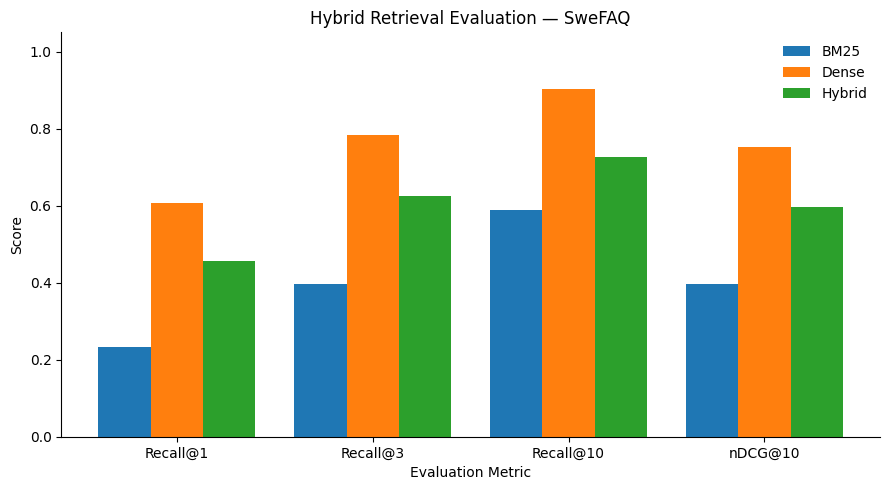

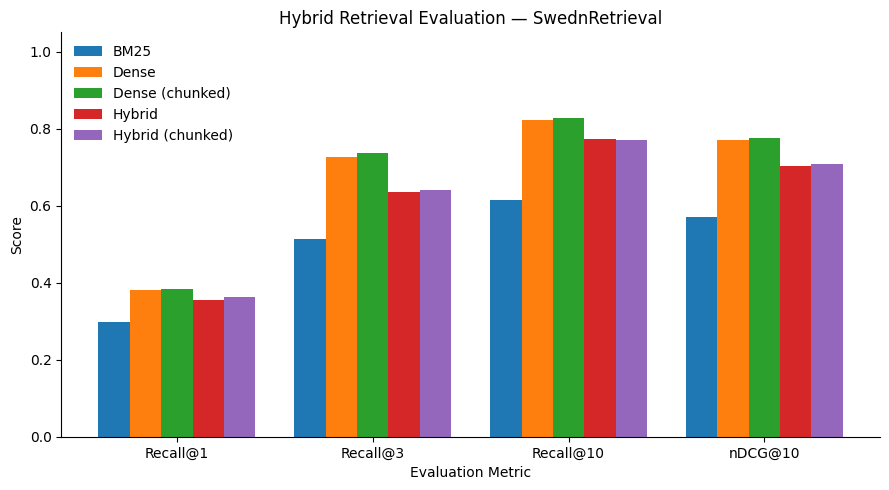

In [29]:
import matplotlib.pyplot as plt
import numpy as np

# Evaluation metrics
metrics = ["Recall@1", "Recall@3", "Recall@10", "nDCG@10"]

# Prepare results
plot_data = all_results.copy()
plot_data["Method"] = plot_data["Method"].astype(str)

# Create separate plots for each dataset
for dataset in plot_data["Dataset"].unique():

    dataset_data = plot_data[plot_data["Dataset"] == dataset]

    x = np.arange(len(metrics))
    n_methods = len(dataset_data)
    width = 0.8 / n_methods

    fig, ax = plt.subplots(figsize=(9, 5))

    for i, (_, row) in enumerate(dataset_data.iterrows()):
        ax.bar(
            x - 0.4 + width / 2 + i * width,
            [row[m] for m in metrics],
            width,
            label=row["Method"]
        )

    ax.set_xlabel("Evaluation Metric")
    ax.set_ylabel("Score")
    ax.set_title(f"Hybrid Retrieval Evaluation — {dataset}")
    ax.set_xticks(x)
    ax.set_xticklabels(metrics)
    ax.set_ylim(0, 1.05)

    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()

# Example

In [38]:
def show_example_hybrid(query_idx, queries, bm25, corpus_ids, corpus_texts, dense_embeddings, qrels_dict, model, k=10):
    q = queries[query_idx]
    qid = q["_id"]
    query_text = q["text"]

    retrieved_ids = search_hybrid(query_text, bm25, corpus_ids, dense_embeddings, model, top_k=k)
    relevant_ids = qrels_dict.get(qid, set())

    id_to_text = dict(zip(corpus_ids, corpus_texts))

    print("QUERY:", query_text)
    print("RELEVANT (gold) IDs:", relevant_ids)
    print()
    print(f"TOP-{k} RETRIEVED (Hybrid):")
    for rank, doc_id in enumerate(retrieved_ids, start=1):
        is_correct = "✅ CORRECT" if doc_id in relevant_ids else ""
        print(f"{rank}. id={doc_id} {is_correct}")
        print(f"   {id_to_text[doc_id][:150]}")
    print("-"*80)

### SweFAQ

In [39]:
show_example_hybrid(
    query_idx=0,
    queries=swefaq_queries,
    bm25=swefaq_bm25,
    corpus_ids=swefaq_corpus_ids,
    corpus_texts=swefaq_corpus_texts,
    dense_embeddings=swefaq_embeddings,
    qrels_dict=swefaq_qrels_dict,
    model=model
)

QUERY: Får jag lägre föräldrapenning om jag går ner i arbetstid innan förlossningen?
RELEVANT (gold) IDs: {'2'}

TOP-10 RETRIEVED (Hybrid):
1. id=2 ✅ CORRECT
   Nej, inte om det är 6 månader eller kortare tid kvar till den planerade förlossningen. Din föräldrapenning beräknas på den inkomst du hade innan du gi
2. id=147 
   Ja, du har rätt att förkorta din arbetstid med upp till 25 procent om du eller en annan förälder får vårdbidrag för barnet. Det gäller även efter att 
3. id=73 
   Ja, men först behöver vi utreda i vilket land du och barnets andra förälder är försäkrade. Om ni är försäkrade i var sitt land kan ni ha rätt till för
4. id=59 
   Om du har varit ledig en månad eller längre har arbetsgivaren rätt att låta dig vänta i högst en månad innan du får börja jobba igen. Det gäller också
5. id=491 
   Under de första 14 dagarna som du är sjukskriven från din föräldraledighet kan du bara få sjukpenning för de dagar då du annars skulle tagit ut föräld
6. id=554 
   Om du får föräld

In [40]:
test_query = "Kan jag ansöka på webben om jag har skyddad identitet?"
for idx, q in enumerate(swefaq_queries):
    if q["text"].strip().lower() == test_query.strip().lower():
        show_example_hybrid(idx, swefaq_queries, swefaq_bm25, swefaq_corpus_ids, swefaq_corpus_texts, swefaq_embeddings, swefaq_qrels_dict, model)
        break

QUERY: Kan jag ansöka på webben om jag har skyddad identitet?
RELEVANT (gold) IDs: {'7'}

TOP-10 RETRIEVED (Hybrid):
1. id=53 
   Nej, om du eller ditt barn har skyddad identitet kan du inte planera eller ansöka på Mina sidor. Det beror på att det kräver inloggning med personnumm
2. id=141 
   Nej. För att kunna ansöka om ersättning för vab på Mina sidor måste båda föräldrar ha svenska personnummer eller samordningsnummer. Om ingen av er har
3. id=276 
   Ja, du kan ansöka om ersättning för reparationskostnader. Du ansöker på Mina sidor. Om du inte kan använda Mina sidor kan du ansöka på blankett.
4. id=10 
   Nej. För att kunna ansöka om 10-dagar på Mina sidor måste båda föräldrarna ha svenska personnummer eller samordningsnummer. Om du har svenskt personnu
5. id=316 
   Om ditt barn inte kan använda Mina sidor för att ansöka om förlängt underhållsstöd hen ansöka på blankett.
6. id=981 
   Nej, alla som är folkbokförda i Sverige och är över 13 år kan ansöka om ett id‑kort, oavsett med

### Swedn

In [42]:
def show_example_hybrid_chunked(query_idx, queries, bm25, corpus_ids, corpus_texts, chunk_embeddings, parent_ids, qrels_dict, model, k=10):
    q = queries[query_idx]
    qid = q["_id"]
    query_text = q["text"]

    retrieved_ids = search_hybrid_chunked(query_text, bm25, corpus_ids, chunk_embeddings, parent_ids, model, top_k=k)
    relevant_ids = qrels_dict.get(qid, set())

    id_to_text = dict(zip(corpus_ids, corpus_texts))

    print("QUERY:", query_text)
    print("RELEVANT (gold) IDs:", relevant_ids)
    print()
    print(f"TOP-{k} RETRIEVED (Hybrid, chunked):")
    for rank, doc_id in enumerate(retrieved_ids, start=1):
        is_correct = "✅ CORRECT" if doc_id in relevant_ids else ""
        print(f"{rank}. id={doc_id} {is_correct}")
        print(f"   {id_to_text[doc_id][:150]}")
    print("-"*80)

In [43]:
test_query = "Ekonom: Avtalet innebär rundgång"
for idx, q in enumerate(swedn_queries):
    if q["text"].strip().lower() == test_query.strip().lower():
        show_example_hybrid_chunked(idx, swedn_queries, swedn_bm25, swedn_corpus_ids, swedn_corpus_texts, swedn_chunk_embeddings, swedn_parent_ids, swedn_qrels_dict, model)
        break

QUERY: Ekonom: Avtalet innebär rundgång
RELEVANT (gold) IDs: {'train_122', 'train_121'}

TOP-10 RETRIEVED (Hybrid, chunked):
1. id=train_545 
   När de brittiska folkvalda på allvar nu ska sätta tänderna i det 585 sidor långa utträdesavtalet som Storbritannien och EU:s 27 andra medlemsländer en
2. id=train_2189 
   Nyhetssajten Axios hänvisar till två källor nära president Donald Trump, som säger att beslutet är fattat. Även CNN uppger att flera officiella källor
3. id=test_2394 
   Regeringen bör konkretisera visionen om ett fossilfritt Sverige utan att förlita sig på framtida negativa utsläpp. De senaste veckornas debatt kring S
4. id=train_896 
   Ratingbyrån Moody´s sänkte på fredagseftermiddagen betyget på Ericssons skulder ett snäpp, från Baa3 till Ba1. Som en följd rasade Ericssonaktien åter
5. id=train_2039 
   DN berättade i går om när barnfamiljen Muda skulle köpa lägenhet genom Erik Olssons fastighetsförmedling. Allt var grönt ända tills säljaren kort före
6. id=train_1886 
